In [13]:
import pandas as pd
import numpy as np

In [14]:
df = pd.read_csv("../data/raw/Loan_status_2007-2020Q3.gzip")

print(df.shape)

C:\Users\oskar\AppData\Local\Temp\ipykernel_20004\3898888804.py:1: DtypeWarning: Columns (0: id, 1: next_pymnt_d, 2: verification_status_joint, 3: sec_app_earliest_cr_line, 4: hardship_type, 5: hardship_reason, 6: hardship_status, 7: hardship_start_date, 8: hardship_end_date, 9: payment_plan_start_date, 10: hardship_loan_status) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("../data/raw/Loan_status_2007-2020Q3.gzip")


(2925493, 142)


In [15]:
df["issue_d"].head()


0    Dec-2011
1    Dec-2011
2    Dec-2011
3    Dec-2011
4    Dec-2011
Name: issue_d, dtype: str

In [16]:
df["issue_d"] = pd.to_datetime(df["issue_d"], format="%b-%Y")


In [17]:
df = df[
    (df["issue_d"].dt.year >= 2014) &
    (df["issue_d"].dt.year <= 2020)
].copy()

print(df.shape)


(2694776, 142)


In [18]:
df = df[
    (df["issue_d"].dt.year >= 2014) &
    (df["issue_d"].dt.year <= 2020)
]

In [19]:
import pandas as pd
import numpy as np

In [20]:
columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "loan_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type"
]

In [21]:
df = pd.read_csv(
    "../data/raw/Loan_status_2007-2020Q3.gzip",
    usecols=columns,
    low_memory=False
)

print(df.shape)

ParserError: Error tokenizing data. C error: out of memory

In [ ]:
import pandas as pd
import numpy as np

In [ ]:
columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "loan_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type"
]

chunks = []

for chunk in pd.read_csv(
    "../data/raw/Loan_status_2007-2020Q3.gzip",
    usecols=columns,
    chunksize=100000,
    low_memory=False
):
    chunk["issue_d"] = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    chunk = chunk[
        (chunk["issue_d"].dt.year >= 2014) &
        (chunk["issue_d"].dt.year <= 2020)
    ]

    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)

print(df.shape)

(2694776, 23)


In [ ]:
df.head()

,id,loan_amnt,term,int_rate,grade,sub_grade,emp_length,home_ownership,annual_inc,verification_status,...,dti,delinq_2yrs,fico_range_low,fico_range_high,inq_last_6mths,open_acc,revol_bal,revol_util,total_acc,application_type
0,120122535,12000.0,36 months,7.97%,A,A5,10+ years,OWN,42000.0,Source Verified,...,27.74,0.0,715.0,719.0,0.0,9.0,11457.0,37%,16.0,Individual
1,119374887,32000.0,36 months,11.99%,B,B5,10+ years,MORTGAGE,155000.0,Source Verified,...,12.35,2.0,715.0,719.0,1.0,20.0,48309.0,34.1%,42.0,Individual
2,119321612,40000.0,60 months,15.05%,C,C4,9 years,MORTGAGE,120000.0,Verified,...,31.11,0.0,765.0,769.0,0.0,12.0,13389.0,20.7%,26.0,Individual
3,120122034,16000.0,36 months,7.97%,A,A5,5 years,RENT,79077.0,Not Verified,...,15.94,0.0,700.0,704.0,0.0,12.0,16217.0,57.7%,20.0,Individual
4,118659541,33000.0,36 months,7.21%,A,A3,< 1 year,MORTGAGE,107000.0,Verified,...,19.06,0.0,785.0,789.0,0.0,25.0,18533.0,16.1%,52.0,Joint App


In [ ]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2694776 entries, 0 to 2694775
Data columns (total 23 columns):
 #   Column               Dtype         
---  ------               -----         
 0   id                   object        
 1   loan_amnt            float64       
 2   term                 str           
 3   int_rate             str           
 4   grade                str           
 5   sub_grade            str           
 6   emp_length           str           
 7   home_ownership       str           
 8   annual_inc           float64       
 9   verification_status  str           
 10  issue_d              datetime64[us]
 11  loan_status          str           
 12  purpose              str           
 13  dti                  float64       
 14  delinq_2yrs          float64       
 15  fico_range_low       float64       
 16  fico_range_high      float64       
 17  inq_last_6mths       float64       
 18  open_acc             float64       
 19  revol_bal            float64    

In [ ]:
df["issue_d"].dt.year.value_counts().sort_index()

issue_d
2014    235629
2015    421095
2016    434407
2017    443579
2018    495242
2019    518107
2020    146717
Name: count, dtype: int64

In [ ]:
df["loan_status"].value_counts()


loan_status
Fully Paid            1305157
Current               1031016
Charged Off            327207
Late (31-120 days)      16154
In Grace Period         10028
Late (16-30 days)        2719
Issued                   2062
Default                   433
Name: count, dtype: int64

In [ ]:
model_df = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

model_df["default_flag"] = (
    model_df["loan_status"] == "Charged Off"
).astype(int)


In [ ]:
model_df["default_flag"].value_counts()

default_flag
0    1305157
1     327207
Name: count, dtype: int64

In [ ]:
model_df["default_flag"].mean()

np.float64(0.2004497771330414)

In [ ]:
model_df.isnull().sum().sort_values(ascending=False)


emp_length             108231
revol_util               1223
dti                      1108
inq_last_6mths              1
int_rate                    0
id                          0
term                        0
loan_amnt                   0
home_ownership              0
sub_grade                   0
grade                       0
annual_inc                  0
loan_status                 0
purpose                     0
issue_d                     0
verification_status         0
fico_range_low              0
delinq_2yrs                 0
open_acc                    0
fico_range_high             0
revol_bal                   0
total_acc                   0
application_type            0
default_flag                0
dtype: int64

In [ ]:
model_df["emp_length"] = model_df["emp_length"].fillna("Unknown")

model_df["revol_util"] = model_df["revol_util"].fillna(
    model_df["revol_util"].median()
)

model_df["dti"] = model_df["dti"].fillna(
    model_df["dti"].median()
)

model_df = model_df.dropna(subset=["inq_last_6mths"])

TypeError: Cannot perform reduction 'median' with string dtype

In [ ]:
model_df["emp_length"] = model_df["emp_length"].fillna("Unknown")

model_df["revol_util"] = model_df["revol_util"].fillna(
    model_df["revol_util"].median()
)

model_df["dti"] = model_df["dti"].fillna(
    model_df["dti"].median()
)

model_df = model_df.dropna(subset=["inq_last_6mths"])

TypeError: Cannot perform reduction 'median' with string dtype

In [ ]:
model_df["revol_util"] = (
    model_df["revol_util"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

In [ ]:
model_df["emp_length"] = model_df["emp_length"].fillna("Unknown")

model_df["revol_util"] = model_df["revol_util"].fillna(
    model_df["revol_util"].median()
)

model_df["dti"] = model_df["dti"].fillna(
    model_df["dti"].median()
)

model_df = model_df.dropna(subset=["inq_last_6mths"])


In [ ]:
model_df.isnull().sum().sum()


np.int64(0)

In [ ]:
model_df["fico"] = (
    model_df["fico_range_low"] + model_df["fico_range_high"]
) / 2

In [ ]:
model_df["fico_band"] = pd.cut(
    model_df["fico"],
    bins=[0, 649, 699, 749, 799, 900],
    labels=["<650", "650-699", "700-749", "750-799", "800+"]
)

In [ ]:
model_df[["fico", "fico_band"]].head(10)


,fico,fico_band
0,717.0,700-749
6,697.0,650-699
7,702.0,700-749
8,662.0,650-699
12,682.0,650-699
13,762.0,750-799
14,677.0,650-699
15,662.0,650-699
16,662.0,650-699
17,662.0,650-699


In [ ]:
model_df["fico_band"].value_counts().sort_index()

fico_band
<650            0
650-699    971727
700-749    517713
750-799    121178
800+        21745
Name: count, dtype: int64

In [ ]:
model_df["dti_band"] = pd.cut(
    model_df["dti"],
    bins=[-1, 20, 30, 40, float("inf")],
    labels=["<20", "20-30", "30-40", "40+"]
)


In [ ]:
model_df["dti_band"].value_counts().sort_index()

dti_band
<20      953654
20-30    497545
30-40    164863
40+       16299
Name: count, dtype: int64

In [ ]:
fico_analysis = model_df.groupby(
    "fico_band",
    observed=True
)["default_flag"].agg(["count", "mean"])

fico_analysis["mean"] = fico_analysis["mean"] * 100

fico_analysis

,count,mean
fico_band,,
650-699,971727,23.475626
700-749,517713,16.388231
750-799,121178,10.395451
800+,21745,7.574155


In [ ]:
dti_analysis = model_df.groupby(
    "dti_band",
    observed=True
)["default_flag"].agg(["count", "mean"])

dti_analysis["mean"] = dti_analysis["mean"] * 100

dti_analysis

,count,mean
dti_band,,
<20,953654,17.405369
20-30,497545,22.394356
30-40,164863,27.283259
40+,16299,29.560096


In [ ]:
fico_dti_analysis = model_df.groupby(
    ["fico_band", "dti_band"],
    observed=True
)["default_flag"].agg(["count", "mean"])

fico_dti_analysis["mean"] = fico_dti_analysis["mean"] * 100

fico_dti_analysis

count       mean
fico_band dti_band                   
650-699   <20       564257  20.567224
          20-30     299913  26.137580
          30-40      98966  31.085423
          40+         8589  33.915473
700-749   <20       292355  14.097245
          20-30     163345  17.930760
          30-40      55894  22.741260
          40+         6119  26.638340
750-799   <20        80725   9.330443
          20-30      30185  11.333444
          30-40       8902  15.681869
          40+         1366  18.155198
800+      <20        16317   7.286879
          20-30       4102   7.849829
          30-40       1101   9.900091
          40+          225  12.000000

In [ ]:
model_df["term"].value_counts()

term
36 months    1220311
60 months     412052
Name: count, dtype: int64

In [ ]:
term_analysis = model_df.groupby(
    "term"
)["default_flag"].agg(["count", "mean"])

term_analysis["mean"] = term_analysis["mean"] * 100

term_analysis


,count,mean
term,,
36 months,1220311,16.076558
60 months,412052,31.797686


In [ ]:
purpose_analysis = model_df.groupby(
    "purpose"
)["default_flag"].agg(["count", "mean"])

purpose_analysis["mean"] = purpose_analysis["mean"] * 100

purpose_analysis = purpose_analysis.sort_values(
    "mean",
    ascending=False
)

purpose_analysis

,count,mean
purpose,,
small_business,15939,29.374490
house,9624,23.140067
moving,11582,22.880332
renewable_energy,1035,22.318841
debt_consolidation,933331,21.231910
medical,20364,20.806325
other,100692,20.266754
major_purchase,35903,19.566610
vacation,12043,18.027070


In [ ]:
grade_analysis = model_df.groupby(
    "grade"
)["default_flag"].agg(["count", "mean"])

grade_analysis["mean"] = grade_analysis["mean"] * 100

grade_analysis = grade_analysis.sort_index()

grade_analysis

,count,mean
grade,,
A,307652,6.542132
B,471944,13.888300
C,469987,22.948294
D,241784,31.144327
E,101398,38.964279
F,30346,46.632176
G,9252,51.005188


In [ ]:
year_analysis = model_df.groupby(
    model_df["issue_d"].dt.year
)["default_flag"].agg(["count", "mean"])

year_analysis["mean"] = year_analysis["mean"] * 100

year_analysis

,count,mean
issue_d,,
2014,235616,17.717388
2015,402819,19.784072
2016,403031,19.603951
2017,314212,21.034206
2018,197074,23.911323
2019,75327,17.904603
2020,4284,1.307190


In [ ]:
status_by_year = pd.crosstab(
    df["issue_d"].dt.year,
    df["loan_status"],
    normalize="index"
) * 100

status_by_year.round(2)


loan_status,Charged Off,Current,Default,Fully Paid,In Grace Period,Issued,Late (16-30 days),Late (31-120 days)
issue_d,,,,,,,,
2014,17.72,0.00,0.00,82.28,0.00,0.00,0.00,0.00
2015,18.93,4.16,0.00,76.73,0.07,0.00,0.02,0.09
2016,18.19,6.93,0.02,74.59,0.11,0.00,0.02,0.14
2017,14.90,27.97,0.04,55.94,0.40,0.00,0.11,0.65
2018,9.52,58.24,0.02,30.28,0.62,0.00,0.17,1.14
2019,2.60,83.33,0.02,11.94,0.71,0.00,0.20,1.20
2020,0.04,94.81,0.00,2.88,0.47,1.41,0.12,0.27


In [ ]:
mature_df = model_df[
    model_df["issue_d"].dt.year <= 2016
].copy()

print(mature_df.shape)

mature_df["issue_d"].dt.year.value_counts().sort_index()


(1041466, 27)


issue_d
2014    235616
2015    402819
2016    403031
Name: count, dtype: int64

In [ ]:
mature_default_rate = mature_df["default_flag"].mean() * 100

print("Default Rate:", round(mature_default_rate, 2), "%")

Default Rate: 19.25 %


In [ ]:
features = [
    "loan_amnt",
    "term",
    "int_rate",
    "annual_inc",
    "dti",
    "fico",
    "revol_util",
    "delinq_2yrs",
    "inq_last_6mths",
    "open_acc",
    "total_acc",
    "emp_length",
    "home_ownership",
    "purpose"
]

target = "default_flag"

In [ ]:
df["income_group"] = pd.qcut(
    df["income"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

income_default = (
    df.groupby("income_group", observed=True)["default"]
      .mean()
)

income_default

KeyError: 'income'

In [ ]:
df.columns.tolist()

['id',
 'loan_amnt',
 'term',
 'int_rate',
 'grade',
 'sub_grade',
 'emp_length',
 'home_ownership',
 'annual_inc',
 'verification_status',
 'issue_d',
 'loan_status',
 'purpose',
 'dti',
 'delinq_2yrs',
 'fico_range_low',
 'fico_range_high',
 'inq_last_6mths',
 'open_acc',
 'revol_bal',
 'revol_util',
 'total_acc',
 'application_type']

In [ ]:
df["income_group"] = pd.qcut(
    df["annual_inc"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

income_default = (
    df.groupby("income_group", observed=True)["default"]
      .mean()
)

income_default

KeyError: 'Column not found: default'

In [ ]:
df["loan_status"].value_counts()


loan_status
Fully Paid            1305157
Current               1031016
Charged Off            327207
Late (31-120 days)      16154
In Grace Period         10028
Late (16-30 days)        2719
Issued                   2062
Default                   433
Name: count, dtype: int64

In [ ]:
df["loan_status"].value_counts()


loan_status
Fully Paid            1305157
Current               1031016
Charged Off            327207
Late (31-120 days)      16154
In Grace Period         10028
Late (16-30 days)        2719
Issued                   2062
Default                   433
Name: count, dtype: int64

In [ ]:
df_model = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

df_model["default"] = (
    df_model["loan_status"] == "Charged Off"
).astype(int)


In [ ]:
df_model["default"].value_counts()


default
0    1305157
1     327207
Name: count, dtype: int64

In [ ]:
df_model["default"].mean()


np.float64(0.2004497771330414)

In [ ]:
df_model["income_group"] = pd.qcut(
    df_model["annual_inc"],
    q=4,
    labels=["Low", "Lower-Middle", "Upper-Middle", "High"]
)

In [ ]:
income_default = (
    df_model.groupby("income_group", observed=True)["default"]
    .mean()
)

income_default

income_group
Low             0.231064
Lower-Middle    0.210807
Upper-Middle    0.193280
High            0.166131
Name: default, dtype: float64

In [ ]:
df_model["dti"].describe()


count    1.631256e+06
mean     1.886970e+01
std      1.365896e+01
min     -1.000000e+00
25%      1.200000e+01
50%      1.796000e+01
75%      2.467000e+01
max      9.990000e+02
Name: dti, dtype: float64

In [ ]:
df_model["dti"].isna().sum()

np.int64(1108)

In [ ]:
df_model["dti"].quantile(
    [0, .01, .05, .25, .50, .75, .95, .99, 1]
)


0.00     -1.00
0.01      1.80
0.05      5.03
0.25     12.00
0.50     17.96
0.75     24.67
0.95     33.87
0.99     39.99
1.00    999.00
Name: dti, dtype: float64

In [ ]:
(df_model["dti"] < 0).sum()


np.int64(2)

In [ ]:
(df_model["dti"] > 40).sum()

np.int64(16299)

In [ ]:
df_model["dti"].isna().sum()

np.int64(1108)

In [ ]:
df_model.loc[df_model["dti"] > 40, "dti"].describe(
    percentiles=[.25, .50, .75, .90, .95, .99]
)


count    16299.000000
mean        71.721028
std         93.112503
min         40.010000
25%         44.020000
50%         49.590000
75%         64.550000
90%         97.500000
95%        146.331000
99%        549.551000
max        999.000000
Name: dti, dtype: float64

In [ ]:
df_model["dti_group"] = pd.cut(
    df_model["dti"],
    bins=[0, 10, 20, 30, 40, float("inf")],
    labels=["0-10", "10-20", "20-30", "30-40", "40+"],
    include_lowest=True
)

In [ ]:
dti_default = (
    df_model.groupby("dti_group", observed=True)["default"]
    .agg(["count", "mean"])
)

dti_default

,count,mean
dti_group,,
0-10,289525,0.161316
10-20,663021,0.179570
20-30,497546,0.223943
30-40,164863,0.272833
40+,16299,0.295601


In [ ]:
df_model["fico"] = (
    df_model["fico_range_low"] + df_model["fico_range_high"]
) / 2

In [ ]:
df_model["fico"].describe()

count    1.632364e+06
mean     6.993565e+02
std      3.281795e+01
min      6.620000e+02
25%      6.720000e+02
50%      6.920000e+02
75%      7.170000e+02
max      8.475000e+02
Name: fico, dtype: float64

In [ ]:
df_model["fico_group"] = pd.cut(
    df_model["fico"],
    bins=[660, 680, 700, 720, 740, 760, 850],
    labels=["660-679", "680-699", "700-719", "720-739", "740-759", "760+"],
    include_lowest=True
)

In [ ]:
fico_default = (
    df_model.groupby("fico_group", observed=True)["default"]
    .agg(["count", "mean"])
)

fico_default

,count,mean
fico_group,,
660-679,546396,0.249094
680-699,425331,0.216337
700-719,299522,0.179379
720-739,167789,0.146851
740-759,88852,0.122023
760+,104474,0.094550


In [ ]:
grade_default = (
    df_model.groupby("grade", observed=True)["default"]
    .agg(["count", "mean"])
)

grade_default

,count,mean
grade,,
A,307652,0.065421
B,471945,0.138883
C,469987,0.229483
D,241784,0.311443
E,101398,0.389643
F,30346,0.466322
G,9252,0.510052


In [ ]:
df_model["int_rate"].describe()

count     1632364
unique        349
top         5.32%
freq        41813
Name: int_rate, dtype: object

In [ ]:
df_model["int_rate_num"] = (
    df_model["int_rate"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

In [ ]:
df_model["int_rate"].describe()

count     1632364
unique        349
top         5.32%
freq        41813
Name: int_rate, dtype: object

In [ ]:
df_model["int_rate_num"] = (
    df_model["int_rate"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

In [ ]:
df_model["int_rate_num"].describe()

count    1.632364e+06
mean     1.307022e+01
std      4.876093e+00
min      5.310000e+00
25%      9.440000e+00
50%      1.262000e+01
75%      1.577000e+01
max      3.099000e+01
Name: int_rate_num, dtype: float64

In [ ]:
df_model["rate_group"] = pd.cut(
    df_model["int_rate_num"],
    bins=[5, 10, 15, 20, 25, 35],
    labels=["5-10%", "10-15%", "15-20%", "20-25%", "25%+"],
    include_lowest=True
)

In [ ]:
rate_default = (
    df_model.groupby("rate_group", observed=True)["default"]
    .agg(["count", "mean"])
)

rate_default

,count,mean
rate_group,,
5-10%,480998,0.083749
10-15%,672400,0.188482
15-20%,351202,0.305548
20-25%,88860,0.389827
25%+,38904,0.468846


In [ ]:
df_model["loan_amnt"].describe()

count    1.632364e+06
mean     1.469708e+04
std      9.081038e+03
min      1.000000e+03
25%      8.000000e+03
50%      1.200000e+04
75%      2.000000e+04
max      4.000000e+04
Name: loan_amnt, dtype: float64

In [ ]:
df_model["loan_size_group"] = pd.cut(
    df_model["loan_amnt"],
    bins=[0, 5000, 10000, 15000, 20000, 30000, 40000],
    labels=["≤5K", "5-10K", "10-15K", "15-20K", "20-30K", "30-40K"],
    include_lowest=True
)

In [ ]:
loan_size_default = (
    df_model.groupby("loan_size_group", observed=True)["default"]
    .agg(["count", "mean"])
)

loan_size_default

In [ ]:
loan_size_default = (
    df_model.groupby("loan_size_group", observed=True)["default"]
    .agg(["count", "mean"])
)

loan_size_default

,count,mean
loan_size_group,,
≤5K,228447,0.149015
5-10K,443633,0.173517
10-15K,334157,0.210257
15-20K,254487,0.228813
20-30K,256254,0.232398
30-40K,115386,0.243920


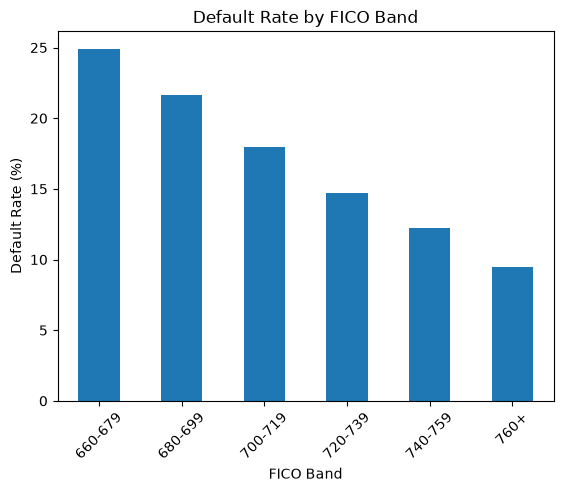

In [ ]:
import matplotlib.pyplot as plt

fico_plot = (
    df_model.groupby("fico_group", observed=True)["default"]
    .mean()
    .mul(100)
)

fico_plot.plot(kind="bar")

plt.title("Default Rate by FICO Band")
plt.xlabel("FICO Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.show()

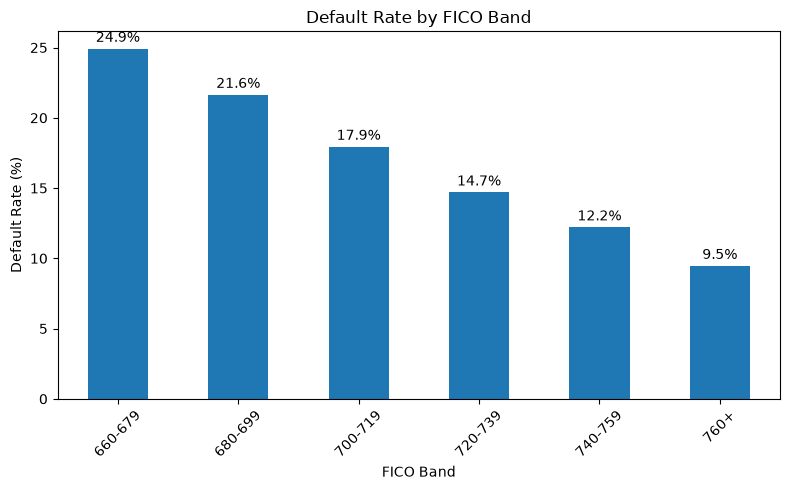

In [ ]:
import matplotlib.pyplot as plt

fico_plot = (
    df_model.groupby("fico_group", observed=True)["default"]
    .mean()
    .mul(100)
)

ax = fico_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by FICO Band")
plt.xlabel("FICO Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)

for i, value in enumerate(fico_plot):
    ax.text(
        i,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

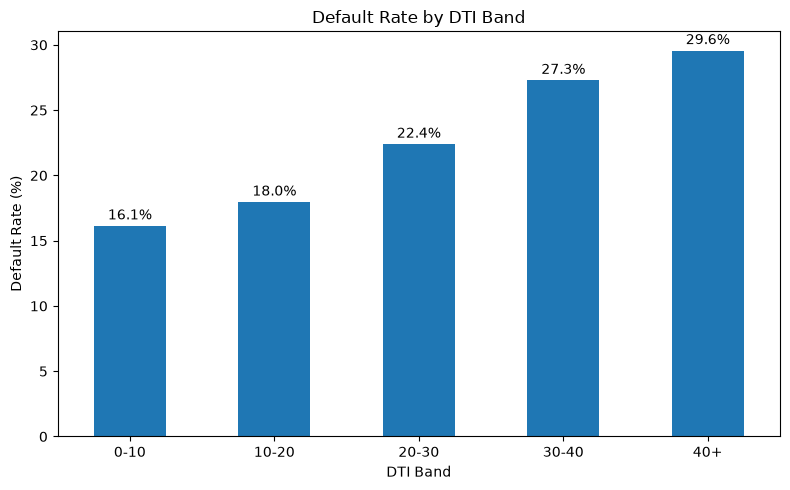

In [ ]:
dti_plot = (
    df_model.groupby("dti_group", observed=True)["default"]
    .mean()
    .mul(100)
)

ax = dti_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by DTI Band")
plt.xlabel("DTI Band")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(dti_plot):
    ax.text(
        i,
        value + 0.5,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

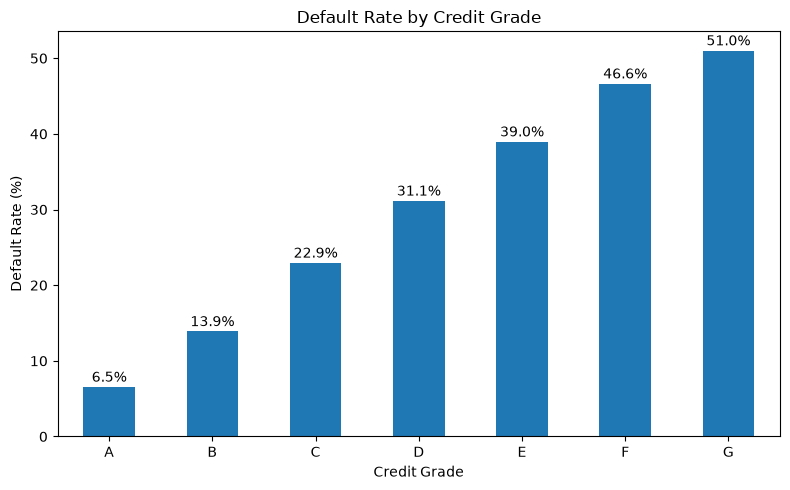

In [ ]:
grade_plot = (
    df_model.groupby("grade", observed=True)["default"]
    .mean()
    .mul(100)
)

ax = grade_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Credit Grade")
plt.xlabel("Credit Grade")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(grade_plot):
    ax.text(
        i,
        value + 0.7,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

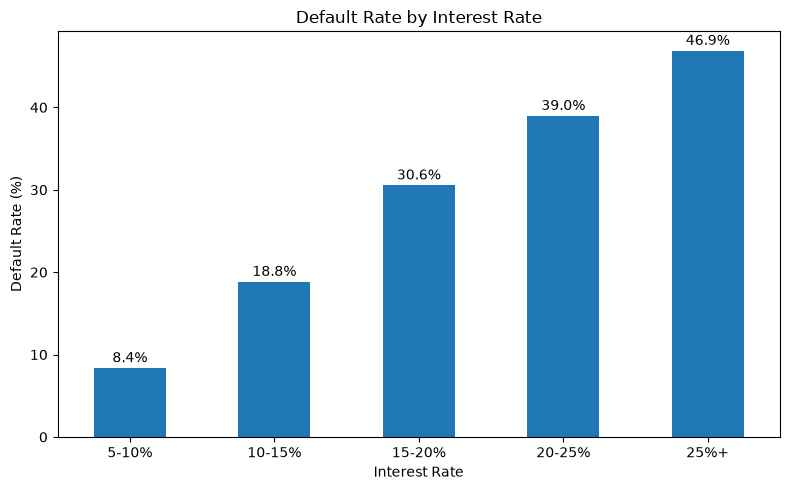

In [ ]:
rate_plot = (
    df_model.groupby("rate_group", observed=True)["default"]
    .mean()
    .mul(100)
)

ax = rate_plot.plot(kind="bar", figsize=(8, 5))

plt.title("Default Rate by Interest Rate")
plt.xlabel("Interest Rate")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=0)

for i, value in enumerate(rate_plot):
    ax.text(
        i,
        value + 0.7,
        f"{value:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()

In [ ]:
fico_dti_risk = (
    df_model.groupby(
        ["fico_group", "dti_group"],
        observed=True
    )["default"]
    .mean()
    .unstack()
    .mul(100)
)

fico_dti_risk.round(1)

dti_group,0-10,10-20,20-30,30-40,40+
fico_group,,,,,
660-679,19.4,22.8,28.2,33.0,36.2
680-699,17.5,19.4,23.7,28.9,31.6
700-719,15.1,15.6,19.5,24.3,28.2
720-739,13.0,12.4,16.1,20.9,25.0
740-759,11.9,10.2,13.3,17.2,21.4
760+,9.8,7.7,10.2,14.6,16.9


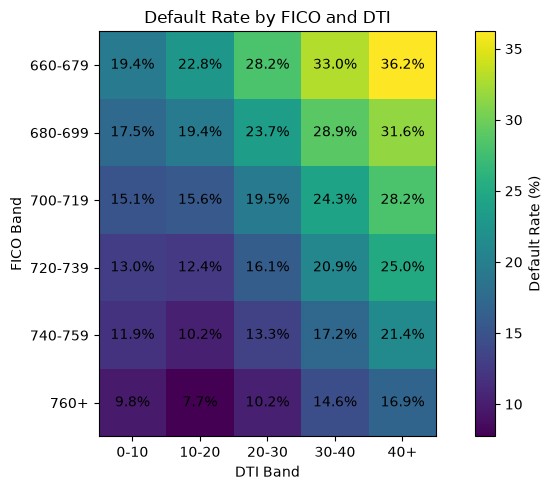

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))

im = ax.imshow(fico_dti_risk)

ax.set_xticks(range(len(fico_dti_risk.columns)))
ax.set_xticklabels(fico_dti_risk.columns)

ax.set_yticks(range(len(fico_dti_risk.index)))
ax.set_yticklabels(fico_dti_risk.index)

ax.set_xlabel("DTI Band")
ax.set_ylabel("FICO Band")
ax.set_title("Default Rate by FICO and DTI")

for i in range(len(fico_dti_risk.index)):
    for j in range(len(fico_dti_risk.columns)):
        value = fico_dti_risk.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.1f}%",
            ha="center",
            va="center"
        )

plt.colorbar(im, label="Default Rate (%)")
plt.tight_layout()
plt.show()

In [ ]:
grade_rate_risk = (
    df_model.groupby(
        ["grade", "rate_group"],
        observed=True
    )["default"]
    .mean()
    .unstack()
    .mul(100)
)

grade_rate_risk.round(1)

rate_group,5-10%,10-15%,15-20%,20-25%,25%+
grade,,,,,
A,6.5,1.1,NaN,NaN,NaN
B,11.6,15.2,1.5,NaN,NaN
C,7.8,21.8,27.6,0.0,NaN
D,7.1,50.0,30.7,36.2,24.2
E,9.1,NaN,37.4,38.7,44.5
F,21.7,NaN,NaN,43.9,50.0
G,12.5,NaN,NaN,NaN,51.0


In [ ]:
grade_rate_count = (
    df_model.groupby(
        ["grade", "rate_group"],
        observed=True
    )["default"]
    .count()
    .unstack()
)

grade_rate_count

rate_group,5-10%,10-15%,15-20%,20-25%,25%+
grade,,,,,
A,307373.0,279.0,NaN,NaN,NaN
B,173245.0,298566.0,134.0,NaN,NaN
C,192.0,373553.0,96200.0,42.0,NaN
D,113.0,2.0,215516.0,24034.0,2119.0
E,44.0,NaN,39352.0,48166.0,13836.0
F,23.0,NaN,NaN,16618.0,13705.0
G,8.0,NaN,NaN,NaN,9244.0


In [ ]:
grade_map = {
    "A": 1,
    "B": 2,
    "C": 3,
    "D": 4,
    "E": 5,
    "F": 6,
    "G": 7
}

df_model["grade_num"] = df_model["grade"].map(grade_map)

In [ ]:
df_model[["grade_num", "int_rate_num"]].corr()

,grade_num,int_rate_num
grade_num,1.000000,0.951418
int_rate_num,0.951418,1.000000


In [ ]:
model_features = [
    "fico",
    "dti",
    "annual_inc",
    "loan_amnt"
]

X = df_model[model_features].copy()

y = df_model["default"].copy()

In [ ]:
X.head()


,fico,dti,annual_inc,loan_amnt
0,717.0,27.74,42000.0,12000.0
6,697.0,18.79,55000.0,10000.0
7,702.0,20.36,120000.0,8000.0
8,662.0,22.63,90000.0,12800.0
12,682.0,38.07,180000.0,15000.0


In [ ]:
y.head()

0     0
6     0
7     0
8     0
12    0
Name: default, dtype: int64

In [ ]:
X.isna().sum()

fico             0
dti           1108
annual_inc       0
loan_amnt        0
dtype: int64

In [ ]:
X = X.dropna()

y = y.loc[X.index]

In [ ]:
X.isna().sum()

fico          0
dti           0
annual_inc    0
loan_amnt     0
dtype: int64

In [ ]:
X.shape

(1631256, 4)

In [ ]:
y.shape

(1631256,)

In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [22]:
df_model.shape

NameError: name 'df_model' is not defined

In [23]:
df = pd.read_csv(
    "../data/raw/loan_status_2007-2020Q3.gzip",
    usecols=columns,
    low_memory=False,
    compression="gzip",
    engine="python"
)

ValueError: The 'low_memory' option is not supported with the 'python' engine

In [24]:
df = pd.read_csv(
    "../data/raw/loan_status_2007-2020Q3.gzip",
    usecols=columns,
    compression="gzip",
    engine="python"
)

BadGzipFile: Not a gzipped file (b',i')

In [25]:
df = pd.read_csv(
    "../data/raw/loan_status_2007-2020Q3.gzip",
    usecols=columns,
    engine="python"
)

MemoryError: Unable to allocate 3.10 GiB for an array with shape (2925493, 142) and data type object

In [1]:
test_columns = [
    "loan_amnt",
    "int_rate",
    "grade",
    "annual_inc",
    "loan_status",
    "dti",
    "fico_range_low",
    "fico_range_high"
]

df_test = pd.read_csv(
    "../data/raw/loan_status_2007-2020Q3.gzip",
    usecols=test_columns,
    engine="python"
)

NameError: name 'pd' is not defined

In [2]:
import pandas as pd

In [ ]:
test_columns = [
    "loan_amnt",
    "int_rate",
    "grade",
    "annual_inc",
    "loan_status",
    "dti",
    "fico_range_low",
    "fico_range_high"
]

df_test = pd.read_csv(
    "../data/raw/loan_status_2007-2020Q3.gzip",
    usecols=test_columns,
    engine="python"
)

In [1]:
columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "loan_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type"
]

chunks = []

for chunk in pd.read_csv(
    "../data/raw/Loan_status_2007-2020Q3.gzip",
    usecols=columns,
    chunksize=100000,
    low_memory=False
):
    chunk["issue_d"] = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    chunk = chunk[
        (chunk["issue_d"].dt.year >= 2014) &
        (chunk["issue_d"].dt.year <= 2020)
    ]

    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)

print(df.shape)

NameError: name 'pd' is not defined

In [2]:
import pandas as pd

In [3]:
columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "term",
    "int_rate",
    "grade",
    "sub_grade",
    "emp_length",
    "home_ownership",
    "annual_inc",
    "verification_status",
    "loan_status",
    "purpose",
    "dti",
    "delinq_2yrs",
    "fico_range_low",
    "fico_range_high",
    "inq_last_6mths",
    "open_acc",
    "revol_bal",
    "revol_util",
    "total_acc",
    "application_type"
]

chunks = []

for chunk in pd.read_csv(
    "../data/raw/Loan_status_2007-2020Q3.gzip",
    usecols=columns,
    chunksize=100000,
    low_memory=False
):
    chunk["issue_d"] = pd.to_datetime(
        chunk["issue_d"],
        format="%b-%Y",
        errors="coerce"
    )

    chunk = chunk[
        (chunk["issue_d"].dt.year >= 2014) &
        (chunk["issue_d"].dt.year <= 2020)
    ]

    chunks.append(chunk)

df = pd.concat(chunks, ignore_index=True)

print(df.shape)

(2694776, 23)


In [4]:
df_model = df[
    df["loan_status"].isin(["Fully Paid", "Charged Off"])
].copy()

df_model["default"] = (
    df_model["loan_status"] == "Charged Off"
).astype(int)

In [5]:
df_model["fico"] = (
    df_model["fico_range_low"] +
    df_model["fico_range_high"]
) / 2

In [6]:
print(df_model.shape)
print(df_model["default"].mean())

(1632364, 25)
0.2004497771330414


In [7]:
from pathlib import Path

Path("../data/processed").mkdir(parents=True, exist_ok=True)

df_model.to_parquet(
    "../data/processed/df_model.parquet",
    index=False
)

ImportError: Unable to find a usable engine; tried using: 'pyarrow', 'fastparquet'.
A suitable version of pyarrow or fastparquet is required for parquet support.
Trying to import the above resulted in these errors:
 - `Import pyarrow` failed. pyarrow is required for parquet support. Use pip or conda to install the pyarrow package.
 - `Import fastparquet` failed. fastparquet is required for parquet support. Use pip or conda to install the fastparquet package.

In [8]:
%pip install pyarrow

   ---------------------------------------- 0.0/28.6 MB ? eta -:--:--
   ------------ --------------------------- 8.7/28.6 MB 55.0 MB/s eta 0:00:01
   --------------------------- ------------ 19.9/28.6 MB 54.6 MB/s eta 0:00:01
   ---------------------------------------  28.6/28.6 MB 53.4 MB/s eta 0:00:01
   ---------------------------------------- 28.6/28.6 MB 42.7 MB/s  0:00:00
Note: you may need to restart the kernel to use updated packages.


In [9]:
df_model.to_parquet(
    "../data/processed/df_model.parquet",
    index=False
)

ArrowKeyError: No type extension with name arrow.py_extension_type found

In [ ]:
df_model.to_pickle(
    "../data/processdf_check = pd.read_pickle(
    "../data/processed/df_model.pkl",
    compression="gzip"
)

print(df_check.shape)
print(df_check["default"].mean())ed/df_model.pkl",
    compression="gzip"
)

In [11]:
df_check = pd.read_pickle(
    "../data/processed/df_model.pkl",
    compression="gzip"
)

print(df_check.shape)
print(df_check["default"].mean())

(1632364, 25)
0.2004497771330414


In [12]:
del df_check

In [13]:
from sklearn.model_selection import train_test_split

model_features = [
    "fico",
    "dti",
    "annual_inc",
    "loan_amnt"
]

X = df_model[model_features].copy()
y = df_model["default"].copy()

# Remove the small number of loans with missing DTI
X = X.dropna()
y = y.loc[X.index]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training loans:", len(X_train))
print("Test loans:", len(X_test))
print("Training default rate:", y_train.mean())
print("Test default rate:", y_test.mean())

Training loans: 1305004
Test loans: 326252
Training default rate: 0.20044919402545894
Test default rate: 0.20044934590439292


In [14]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is '

In [15]:
import pandas as pd

coefficients = pd.DataFrame({
    "Feature": model_features,
    "Coefficient": model.coef_[0]
})

coefficients

,Feature,Coefficient
0,fico,-0.377415
1,dti,0.112495
2,annual_inc,-0.625715
3,loan_amnt,0.312359


In [16]:
from sklearn.metrics import roc_auc_score, accuracy_score

# Predict default probabilities
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Predict 0 or 1 using the model's default threshold
y_pred = model.predict(X_test_scaled)

auc = roc_auc_score(y_test, y_prob)
accuracy = accuracy_score(y_test, y_pred)

print("ROC-AUC:", round(auc, 4))
print("Accuracy:", round(accuracy, 4))

ROC-AUC: 0.6321
Accuracy: 0.7992


In [17]:
from sklearn.metrics import confusion_matrix, classification_report

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Confusion Matrix:
[[260658    197]
 [ 65303     94]]

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89    260855
           1       0.32      0.00      0.00     65397

    accuracy                           0.80    326252
   macro avg       0.56      0.50      0.45    326252
weighted avg       0.70      0.80      0.71    326252



In [18]:
import pandas as pd

pd.Series(y_prob).describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
)

count    3.262520e+05
mean     2.005640e-01
std      7.086276e-02
min      8.786607e-24
10%      1.092870e-01
25%      1.537165e-01
50%      2.003774e-01
75%      2.446818e-01
90%      2.879348e-01
95%      3.169374e-01
99%      3.745224e-01
max      9.996972e-01
dtype: float64

In [19]:
risk_results = pd.DataFrame({
    "actual_default": y_test.values,
    "predicted_probability": y_prob
})

risk_results["risk_decile"] = pd.qcut(
    risk_results["predicted_probability"],
    q=10,
    labels=[
        "1 - Lowest",
        "2",
        "3",
        "4",
        "5",
        "6",
        "7",
        "8",
        "9",
        "10 - Highest"
    ]
)

decile_summary = (
    risk_results
    .groupby("risk_decile", observed=True)
    .agg(
        loans=("actual_default", "count"),
        defaults=("actual_default", "sum"),
        actual_default_rate=("actual_default", "mean"),
        avg_predicted_probability=("predicted_probability", "mean")
    )
)

decile_summary["actual_default_rate"] *= 100
decile_summary["avg_predicted_probability"] *= 100

decile_summary

,loans,defaults,actual_default_rate,avg_predicted_probability
risk_decile,,,,
1 - Lowest,32626,2688,8.238828,8.036625
2,32625,3975,12.183908,12.665515
3,32625,4835,14.819923,15.353644
4,32625,5502,16.864368,17.417336
5,32625,5886,18.041379,19.192487
6,32625,6540,20.045977,20.872065
7,32625,7246,22.209962,22.577193
8,32625,8284,25.391571,24.498677
9,32625,9334,28.609962,27.058790


In [20]:
total_defaults = risk_results["actual_default"].sum()

top_10_defaults = decile_summary.loc[
    "10 - Highest", "defaults"
]

top_20_defaults = (
    decile_summary.loc["9", "defaults"] +
    decile_summary.loc["10 - Highest", "defaults"]
)

top_30_defaults = (
    decile_summary.loc["8", "defaults"] +
    decile_summary.loc["9", "defaults"] +
    decile_summary.loc["10 - Highest", "defaults"]
)

print(
    "Top 10% of loans capture:",
    round(top_10_defaults / total_defaults * 100, 2),
    "% of defaults"
)

print(
    "Top 20% of loans capture:",
    round(top_20_defaults / total_defaults * 100, 2),
    "% of defaults"
)

print(
    "Top 30% of loans capture:",
    round(top_30_defaults / total_defaults * 100, 2),
    "% of defaults"
)

Top 10% of loans capture: 16.98 % of defaults
Top 20% of loans capture: 31.26 % of defaults
Top 30% of loans capture: 43.92 % of defaults


In [21]:
full_features = [
    "fico",
    "dti",
    "annual_inc",
    "loan_amnt",
    "int_rate_num"
]

X_full = df_model[full_features].copy()
y_full = df_model["default"].copy()

X_full = X_full.dropna()
y_full = y_full.loc[X_full.index]

print(X_full.shape)
print(y_full.mean())

KeyError: "['int_rate_num'] not in index"

In [22]:
df_model["int_rate_num"] = (
    df_model["int_rate"]
    .str.replace("%", "", regex=False)
    .astype(float)
)

In [23]:
df_model[["int_rate", "int_rate_num"]].head()

,int_rate,int_rate_num
0,7.97%,7.97
6,9.44%,9.44
7,16.02%,16.02
8,13.59%,13.59
12,13.59%,13.59


In [24]:
full_features = [
    "fico",
    "dti",
    "annual_inc",
    "loan_amnt",
    "int_rate_num"
]

X_full = df_model[full_features].copy()
y_full = df_model["default"].copy()

X_full = X_full.dropna()
y_full = y_full.loc[X_full.index]

print(X_full.shape)
print(y_full.mean())

(1631256, 5)
0.2004492244013202


In [25]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score

# Split the data
X_full_train, X_full_test, y_full_train, y_full_test = train_test_split(
    X_full,
    y_full,
    test_size=0.20,
    random_state=42,
    stratify=y_full
)

# Standardize the features
scaler_full = StandardScaler()

X_full_train_scaled = scaler_full.fit_transform(X_full_train)
X_full_test_scaled = scaler_full.transform(X_full_test)

# Train logistic regression
model_full = LogisticRegression(max_iter=1000)
model_full.fit(X_full_train_scaled, y_full_train)

# Generate predictions
y_full_prob = model_full.predict_proba(
    X_full_test_scaled
)[:, 1]

y_full_pred = model_full.predict(
    X_full_test_scaled
)

# Evaluate
auc_full = roc_auc_score(y_full_test, y_full_prob)
accuracy_full = accuracy_score(y_full_test, y_full_pred)

print("Model 1 ROC-AUC:", round(auc, 4))
print("Model 2 ROC-AUC:", round(auc_full, 4))
print()
print("Model 1 Accuracy:", round(accuracy, 4))
print("Model 2 Accuracy:", round(accuracy_full, 4))

Model 1 ROC-AUC: 0.6321
Model 2 ROC-AUC: 0.6914

Model 1 Accuracy: 0.7992
Model 2 Accuracy: 0.799


In [26]:
coefficients_full = pd.DataFrame({
    "Feature": full_features,
    "Coefficient": model_full.coef_[0]
})

coefficients_full["Abs_Coefficient"] = (
    coefficients_full["Coefficient"].abs()
)

coefficients_full = coefficients_full.sort_values(
    "Abs_Coefficient",
    ascending=False
)

coefficients_full

,Feature,Coefficient,Abs_Coefficient
4,int_rate_num,0.537041,0.537041
2,annual_inc,-0.371947,0.371947
3,loan_amnt,0.188060,0.188060
0,fico,-0.157839,0.157839
1,dti,0.046636,0.046636


In [27]:
risk_results_full = pd.DataFrame({
    "actual_default": y_full_test.values,
    "predicted_probability": y_full_prob
})

risk_results_full["risk_decile"] = pd.qcut(
    risk_results_full["predicted_probability"],
    q=10,
    labels=[
        "1 - Lowest",
        "2",
        "3",
        "4",
        "5",
        "6",
        "7",
        "8",
        "9",
        "10 - Highest"
    ]
)

decile_summary_full = (
    risk_results_full
    .groupby("risk_decile", observed=True)
    .agg(
        loans=("actual_default", "count"),
        defaults=("actual_default", "sum"),
        actual_default_rate=("actual_default", "mean"),
        avg_predicted_probability=("predicted_probability", "mean")
    )
)

decile_summary_full["actual_default_rate"] *= 100
decile_summary_full["avg_predicted_probability"] *= 100

decile_summary_full

,loans,defaults,actual_default_rate,avg_predicted_probability
risk_decile,,,,
1 - Lowest,32626,1635,5.011341,6.944754
2,32625,2856,8.754023,9.943199
3,32625,3721,11.405364,12.186425
4,32625,4633,14.200766,14.335667
5,32625,5460,16.735632,16.473515
6,32625,6404,19.629119,18.746394
7,32625,7542,23.117241,21.405799
8,32625,8954,27.445211,25.014639
9,32625,10681,32.738697,30.672376


In [28]:
total_defaults_full = risk_results_full["actual_default"].sum()

top_10_full = (
    decile_summary_full.loc["10 - Highest", "defaults"]
    / total_defaults_full * 100
)

top_20_full = (
    (
        decile_summary_full.loc["9", "defaults"]
        + decile_summary_full.loc["10 - Highest", "defaults"]
    )
    / total_defaults_full * 100
)

top_30_full = (
    (
        decile_summary_full.loc["8", "defaults"]
        + decile_summary_full.loc["9", "defaults"]
        + decile_summary_full.loc["10 - Highest", "defaults"]
    )
    / total_defaults_full * 100
)

capture_comparison = pd.DataFrame({
    "Portfolio Segment": ["Top 10%", "Top 20%", "Top 30%"],
    "Model 1": [16.98, 31.26, 43.92],
    "Model 2": [top_10_full, top_20_full, top_30_full]
})

capture_comparison.round(2)

,Portfolio Segment,Model 1,Model 2
0,Top 10%,16.98,20.66
1,Top 20%,31.26,36.99
2,Top 30%,43.92,50.68


In [29]:
risk_results_full["risk_tier"] = pd.cut(
    risk_results_full["predicted_probability"],
    bins=[
        -float("inf"),
        risk_results_full["predicted_probability"].quantile(0.30),
        risk_results_full["predicted_probability"].quantile(0.60),
        risk_results_full["predicted_probability"].quantile(0.80),
        float("inf")
    ],
    labels=[
        "Low",
        "Moderate",
        "Elevated",
        "High"
    ]
)

In [30]:
tier_summary = (
    risk_results_full
    .groupby("risk_tier", observed=True)
    .agg(
        loans=("actual_default", "count"),
        defaults=("actual_default", "sum"),
        actual_default_rate=("actual_default", "mean"),
        avg_predicted_probability=("predicted_probability", "mean")
    )
)

tier_summary["actual_default_rate"] *= 100
tier_summary["avg_predicted_probability"] *= 100

tier_summary.round(2)

,loans,defaults,actual_default_rate,avg_predicted_probability
risk_tier,,,,
Low,97876,8212,8.39,9.69
Moderate,97875,16497,16.86,16.52
Elevated,65250,16496,25.28,23.21
High,65251,24192,37.08,37.76


In [31]:
total_defaults = tier_summary["defaults"].sum()

tier_summary["default_capture_rate"] = (
    tier_summary["defaults"] / total_defaults * 100
)

tier_summary.round(2)

,loans,defaults,actual_default_rate,avg_predicted_probability,default_capture_rate
risk_tier,,,,,
Low,97876,8212,8.39,9.69,12.56
Moderate,97875,16497,16.86,16.52,25.23
Elevated,65250,16496,25.28,23.21,25.22
High,65251,24192,37.08,37.76,36.99


## Business Recommendations

The enhanced credit risk model provides meaningful segmentation of the portfolio and can be used to prioritize monitoring resources.

- The highest-risk 20% of loans had an actual default rate of 37.1% and accounted for 37.0% of all defaults.
- The lowest-risk 30% had an actual default rate of 8.4% and accounted for 12.6% of defaults.

### Recommended Monitoring Approach

- **Low Risk:** Routine portfolio monitoring
- **Moderate Risk:** Standard monitoring and periodic trend review
- **Elevated Risk:** Enhanced monitoring and deeper borrower-level review
- **High Risk:** Priority analyst review and concentrated monitoring resources

In [32]:
import sqlite3

conn = sqlite3.connect("../data/credit_risk.db")

In [ ]:
sql_columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "int_rate_num",
    "grade",
    "annual_inc",
    "dti",
    "fico",
    "purpose",
    "home_ownership",
    "term",
    "default"
]

df_sql = df_model[sql_columns].copy()

print(df
      sql.shape)
df_sql.head()

(1632364, 12)


,id,issue_d,loan_amnt,int_rate_num,grade,annual_inc,dti,fico,purpose,home_ownership,term,default
0,120122535,2017-09-01,12000.0,7.97,A,42000.0,27.74,717.0,debt_consolidation,OWN,36 months,0
6,119183129,2017-09-01,10000.0,9.44,B,55000.0,18.79,697.0,debt_consolidation,MORTGAGE,36 months,0
7,120086024,2017-09-01,8000.0,16.02,C,120000.0,20.36,702.0,debt_consolidation,MORTGAGE,36 months,0
8,119417303,2017-09-01,12800.0,13.59,C,90000.0,22.63,662.0,debt_consolidation,RENT,36 months,0
12,119997711,2017-09-01,15000.0,13.59,C,180000.0,38.07,682.0,medical,MORTGAGE,36 months,0


In [34]:
df_sql.to_sql(
    "loans",
    conn,
    if_exists="replace",
    index=False
)

1632364

In [35]:
query = """
SELECT
    COUNT(*) AS total_loans,
    SUM(default) AS total_defaults,
    ROUND(AVG(default) * 100, 2) AS default_rate
FROM loans;
"""

pd.read_sql_query(query, conn)

DatabaseError: Execution failed on sql '
SELECT
    COUNT(*) AS total_loans,
    SUM(default) AS total_defaults,
    ROUND(AVG(default) * 100, 2) AS default_rate
FROM loans;
': near "default": syntax error

In [36]:
df_sql = df_sql.rename(
    columns={"default": "default_flag"}
)

df_sql.to_sql(
    "loans",
    conn,
    if_exists="replace",
    index=False
)

1632364

In [37]:
query = """
SELECT
    COUNT(*) AS total_loans,
    SUM(default_flag) AS total_defaults,
    ROUND(AVG(default_flag) * 100, 2) AS default_rate
FROM loans;
"""

pd.read_sql_query(query, conn)

,total_loans,total_defaults,default_rate
0,1632364,327207,20.04


In [38]:
query = """
SELECT
    grade,
    COUNT(*) AS total_loans,
    SUM(default_flag) AS total_defaults,
    ROUND(AVG(default_flag) * 100, 2) AS default_rate
FROM loans
GROUP BY grade
ORDER BY grade;
"""

grade_sql = pd.read_sql_query(query, conn)

grade_sql

,grade,total_loans,total_defaults,default_rate
0,A,307652,20127,6.54
1,B,471945,65545,13.89
2,C,469987,107854,22.95
3,D,241784,75302,31.14
4,E,101398,39509,38.96
5,F,30346,14151,46.63
6,G,9252,4719,51.01


In [39]:
query = """
SELECT
    CASE
        WHEN fico < 680 THEN '660-679'
        WHEN fico < 700 THEN '680-699'
        WHEN fico < 720 THEN '700-719'
        WHEN fico < 740 THEN '720-739'
        WHEN fico < 760 THEN '740-759'
        ELSE '760+'
    END AS fico_band,

    COUNT(*) AS total_loans,
    SUM(default_flag) AS total_defaults,
    ROUND(AVG(default_flag) * 100, 2) AS default_rate

FROM loans

GROUP BY fico_band

ORDER BY
    CASE fico_band
        WHEN '660-679' THEN 1
        WHEN '680-699' THEN 2
        WHEN '700-719' THEN 3
        WHEN '720-739' THEN 4
        WHEN '740-759' THEN 5
        WHEN '760+' THEN 6
    END;
"""

fico_sql = pd.read_sql_query(query, conn)

fico_sql

,fico_band,total_loans,total_defaults,default_rate
0,660-679,546396,136104,24.91
1,680-699,425331,92015,21.63
2,700-719,299522,53728,17.94
3,720-739,167789,24640,14.69
4,740-759,88852,10842,12.20
5,760+,104474,9878,9.45


In [40]:
query = """
WITH risk_bands AS (
    SELECT
        default_flag,

        CASE
            WHEN fico < 680 THEN '660-679'
            WHEN fico < 700 THEN '680-699'
            WHEN fico < 720 THEN '700-719'
            WHEN fico < 740 THEN '720-739'
            WHEN fico < 760 THEN '740-759'
            ELSE '760+'
        END AS fico_band,

        CASE
            WHEN dti < 10 THEN '0-10'
            WHEN dti < 20 THEN '10-20'
            WHEN dti < 30 THEN '20-30'
            WHEN dti < 40 THEN '30-40'
            ELSE '40+'
        END AS dti_band

    FROM loans
    WHERE dti IS NOT NULL
)

SELECT
    fico_band,
    dti_band,
    COUNT(*) AS total_loans,
    SUM(default_flag) AS total_defaults,
    ROUND(AVG(default_flag) * 100, 2) AS default_rate

FROM risk_bands

GROUP BY
    fico_band,
    dti_band

ORDER BY
    fico_band,
    dti_band;
"""

fico_dti_sql = pd.read_sql_query(query, conn)

fico_dti_sql.head(10)

,fico_band,dti_band,total_loans,total_defaults,default_rate
0,660-679,0-10,97685,18969,19.42
1,660-679,10-20,226770,51778,22.83
2,660-679,20-30,164479,46300,28.15
3,660-679,30-40,52931,17438,32.94
4,660-679,40+,4293,1555,36.22
5,680-699,0-10,66600,11654,17.50
6,680-699,10-20,172217,33387,19.39
7,680-699,20-30,135653,32143,23.70
8,680-699,30-40,46320,13402,28.93
9,680-699,40+,4301,1359,31.60


In [41]:
query = """
SELECT
    CAST(strftime('%Y', issue_d) AS INTEGER) AS issue_year,
    COUNT(*) AS total_loans,
    ROUND(SUM(loan_amnt), 0) AS total_originations,
    ROUND(AVG(loan_amnt), 0) AS avg_loan_amount,
    SUM(default_flag) AS total_defaults,
    ROUND(AVG(default_flag) * 100, 2) AS default_rate

FROM loans

GROUP BY issue_year

ORDER BY issue_year;
"""

year_sql = pd.read_sql_query(query, conn)

year_sql

,issue_year,total_loans,total_originations,avg_loan_amount,total_defaults,default_rate
0,2014,235616,3.503601e+09,14870.0,41745,17.72
1,2015,402819,6.048600e+09,15016.0,79694,19.78
2,2016,403032,5.760185e+09,14292.0,79010,19.60
3,2017,314212,4.472359e+09,14234.0,66092,21.03
4,2018,197074,3.021516e+09,15332.0,47123,23.91
5,2019,75327,1.125649e+09,14944.0,13487,17.90
6,2020,4284,5.907808e+07,13790.0,56,1.31


In [42]:
tableau_columns = [
    "id",
    "issue_d",
    "loan_amnt",
    "grade",
    "fico",
    "dti",
    "annual_inc",
    "int_rate_num",
    "purpose",
    "home_ownership",
    "term",
    "default"
]

df_tableau = df_model[tableau_columns].copy()

print(df_tableau.shape)
df_tableau.head()

(1632364, 12)


,id,issue_d,loan_amnt,grade,fico,dti,annual_inc,int_rate_num,purpose,home_ownership,term,default
0,120122535,2017-09-01,12000.0,A,717.0,27.74,42000.0,7.97,debt_consolidation,OWN,36 months,0
6,119183129,2017-09-01,10000.0,B,697.0,18.79,55000.0,9.44,debt_consolidation,MORTGAGE,36 months,0
7,120086024,2017-09-01,8000.0,C,702.0,20.36,120000.0,16.02,debt_consolidation,MORTGAGE,36 months,0
8,119417303,2017-09-01,12800.0,C,662.0,22.63,90000.0,13.59,debt_consolidation,RENT,36 months,0
12,119997711,2017-09-01,15000.0,C,682.0,38.07,180000.0,13.59,medical,MORTGAGE,36 months,0


In [43]:
df_tableau["fico_band"] = pd.cut(
    df_tableau["fico"],
    bins=[660, 680, 700, 720, 740, 760, 850],
    labels=[
        "660-679",
        "680-699",
        "700-719",
        "720-739",
        "740-759",
        "760+"
    ],
    include_lowest=True
)

df_tableau["dti_band"] = pd.cut(
    df_tableau["dti"],
    bins=[0, 10, 20, 30, 40, float("inf")],
    labels=[
        "0-10",
        "10-20",
        "20-30",
        "30-40",
        "40+"
    ],
    include_lowest=True
)

In [44]:
df_tableau["issue_year"] = df_tableau["issue_d"].dt.year

In [45]:
df_tableau.to_csv(
    "../data/processed/tableau_credit_risk.csv",
    index=False
)

print(df_tableau.shape)

(1632364, 15)
